# Previsão do fechamento - VALE3 

Notas das versões:
- v1: previa o preço direto → bem pior que o baseline (MAE 1,29 x 0,73)
- v2: prevendo a variação do dia seguinte → empate com o baseline
- v3: +5 features técnicas, walk-forward e stats p/ drift → não melhorou
- v4 (esta): dados desde 2008 + BHP, Rio Tinto, Baosteel, Ibovespa e dólar

In [1]:
import json
import time
from datetime import datetime

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import sklearn
import tensorflow as tf
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.models import Sequential

tf.keras.utils.set_random_seed(42)

## Dados

Yahoo direto pela API de chart (o yfinance tava dando problema).
Close = ajustado (uso p/ treinar, senão os dividendos viram quedas falsas). CloseBruto = preço real, igual ao do Google.

In [2]:
TICKER = "VALE3.SA"
INICIO = "2008-01-01"


def baixar_direto(ticker, inicio):
    url = f"https://query1.finance.yahoo.com/v8/finance/chart/{ticker}"
    params = {
        "period1": int(pd.Timestamp(inicio).timestamp()),
        "period2": int(time.time()),
        "interval": "1d",
        "events": "history",
    }
    r = requests.get(url, params=params, headers={"User-Agent": "Mozilla/5.0"}, timeout=30)
    r.raise_for_status()
    res = r.json()["chart"]["result"][0]
    ind = res["indicators"]
    cotacao = ind["quote"][0]
    ajustado = ind["adjclose"][0]["adjclose"] if "adjclose" in ind else cotacao["close"]
    datas = pd.to_datetime(res["timestamp"], unit="s").normalize()
    return pd.DataFrame(
        {
            "Close": ajustado,
            "High": cotacao["high"],
            "Low": cotacao["low"],
            "CloseBruto": cotacao["close"],
            "Volume": cotacao["volume"],
        },
        index=datas,
    )


dados_brutos = baixar_direto(TICKER, INICIO)
print("Linhas baixadas:", len(dados_brutos))
dados_brutos.tail()

Linhas baixadas: 4678


,Close,High,Low,CloseBruto,Volume
2026-10-23,61.900002,62.259998,61.500000,61.900002,26996200
2026-10-26,64.379997,67.989998,64.160004,64.379997,92311400
2026-10-27,63.000000,64.430000,62.639999,63.000000,43938600
2026-10-28,61.380001,62.900002,60.860001,61.380001,38289400
2026-10-29,60.049999,61.540001,60.049999,60.049999,23534700


**Tratamento**(limpeza): vazios, datas duplicadas e volume zero

In [3]:
print("Vazios por coluna:")
print(dados_brutos.isna().sum().to_string())
print("Datas repetidas:", int(dados_brutos.index.duplicated().sum()))
print("Dias com volume zero:", int((dados_brutos["Volume"] == 0).sum()))

df = dados_brutos.dropna()
df = df[~df.index.duplicated(keep="last")]
df = df[df["Volume"] > 0]

print("Linhas após limpeza:", len(df), f"({df.index.min().date()} a {df.index.max().date()})")

Vazios por coluna:
Close         0
High          0
Low           0
CloseBruto    0
Volume        0
Datas repetidas: 0
Dias com volume zero: 30
Linhas após limpeza: 4648 (2008-01-02 a 2026-10-29)


dias extremos (2008, Brumadinho, Covid) → mantive, aconteceram de verdade

5 maiores variações (%):
2019-01-28   -24.56
2020-03-13    21.36
2008-10-15   -18.58
2020-03-10    18.45
2020-03-09   -15.20


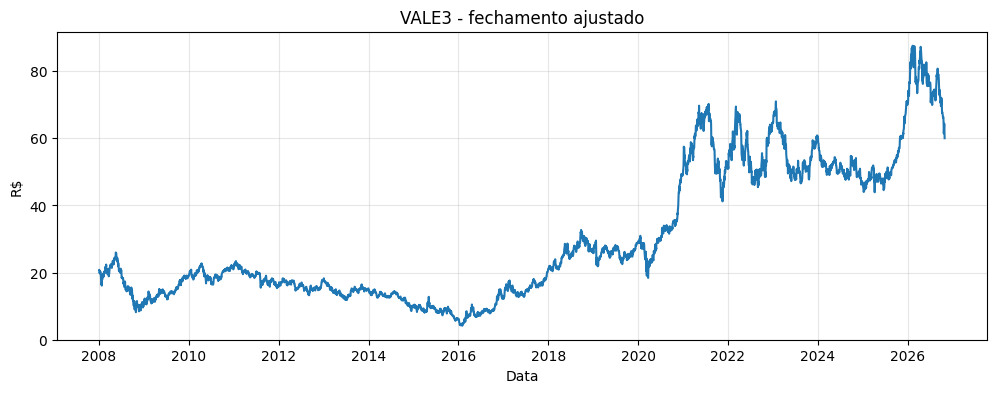

In [4]:
variacao_diaria = df["Close"].pct_change()
maiores = variacao_diaria.abs().sort_values(ascending=False).head(5).index
print("5 maiores variações (%):")
print((variacao_diaria.loc[maiores] * 100).round(2).to_string())

plt.figure(figsize=(12, 4))
plt.plot(df.index, df["Close"])
plt.title("VALE3 - fechamento ajustado")
plt.xlabel("Data")
plt.ylabel("R$")
plt.grid(alpha=0.3)
plt.show()

## Mercado

BHP e Rio Tinto (concorrentes), Baosteel (empresa listada do grupo China Baowu, compra minério), Ibovespa e dólar.
Feriados diferentes em cada bolsa → alinho nas datas da Vale e repito o último preço (ffill).

In [5]:
MERCADO = {
    "bhp": "BHP",
    "rio": "RIO",
    "baosteel": "600019.SS",
    "ibov": "^BVSP",
    "dolar": "BRL=X",
}


def baixar_mercado(tickers, inicio, datas_referencia):
    series = {}
    for nome, ticker in tickers.items():
        try:
            serie = baixar_direto(ticker, inicio)["Close"].dropna()
            serie = serie[~serie.index.duplicated(keep="last")]
            serie = serie.reindex(serie.index.union(datas_referencia)).ffill().reindex(datas_referencia)
            series[nome] = serie
            print(f"{nome}: ok, desde {serie.first_valid_index().date()}")
        except Exception as erro:
            print(f"{nome}: falhou ({erro})")
        time.sleep(1)
    return pd.DataFrame(series)


mercado = baixar_mercado(MERCADO, INICIO, df.index)
mercado.tail()

bhp: ok, desde 2008-01-02
rio: ok, desde 2008-01-02
baosteel: ok, desde 2008-01-02
ibov: ok, desde 2008-01-02
dolar: ok, desde 2008-01-02


,bhp,rio,baosteel,ibov,dolar
2026-10-23,77.849998,83.419998,5.88,205083.000000,5.0499
2026-10-26,79.129997,83.720001,6.00,176608.000000,4.9602
2026-10-27,82.599998,85.739998,6.00,175710.000000,5.3726
2026-10-28,82.220001,85.930000,6.01,171006.000000,5.3503
2026-10-29,81.820000,83.250000,6.00,169186.421875,5.3835


## Features

alvo = variação do dia seguinte (Close ajustado)

In [6]:
FEATURES_TECNICAS = ["retorno", "amplitude", "volume_rel", "volatilidade_20", "dist_media_20"]
FEATURES_MERCADO = [f"retorno_{nome}" for nome in mercado.columns]
FEATURES = FEATURES_TECNICAS + FEATURES_MERCADO


def preparar_features(df, mercado=None):
    f = pd.DataFrame(index=df.index)
    f["retorno"] = df["Close"].pct_change()
    f["amplitude"] = (df["High"] - df["Low"]) / df["CloseBruto"]
    f["volume_rel"] = np.log(df["Volume"] / df["Volume"].rolling(20).mean())
    f["volatilidade_20"] = f["retorno"].rolling(20).std()
    f["dist_media_20"] = df["Close"] / df["Close"].rolling(20).mean() - 1
    if mercado is not None:
        for nome in mercado.columns:
            f[f"retorno_{nome}"] = mercado[nome].pct_change()
    return f


tabela = preparar_features(df, mercado)
tabela["Close"] = df["Close"]
tabela["CloseBruto"] = df["CloseBruto"]
tabela["alvo"] = df["Close"].shift(-1) / df["Close"] - 1
tabela = tabela.replace([np.inf, -np.inf], np.nan)
tabela = tabela.dropna(subset=FEATURES)

dados = tabela.dropna(subset=["alvo"])  # último dia não tem alvo
print("Dias p/ treino e teste:", len(dados), f"({dados.index[0].date()} a {dados.index[-1].date()})")
dados[FEATURES].describe().round(4)

Dias p/ treino e teste: 4627 (2008-01-31 a 2026-10-28)


,retorno,amplitude,volume_rel,volatilidade_20,dist_media_20,retorno_bhp,retorno_rio,retorno_baosteel,retorno_ibov,retorno_dolar
count,4627.0000,4627.0000,4627.0000,4627.0000,4627.0000,4627.0000,4627.0000,4627.0000,4627.0000,4627.0000
mean,0.0006,0.0290,-0.0978,0.0231,0.0034,0.0006,0.0006,0.0002,0.0004,0.0003
std,0.0258,0.0182,0.6243,0.0119,0.0591,0.0235,0.0265,0.0217,0.0164,0.0113
min,-0.2456,0.0000,-8.4960,0.0039,-0.2575,-0.1715,-0.2733,-0.1005,-0.1478,-0.1048
25%,-0.0129,0.0176,-0.3080,0.0161,-0.0324,-0.0109,-0.0117,-0.0088,-0.0077,-0.0048
50%,0.0000,0.0245,-0.0712,0.0198,0.0049,0.0004,0.0002,0.0000,0.0003,0.0000
75%,0.0130,0.0342,0.1770,0.0264,0.0378,0.0124,0.0125,0.0088,0.0086,0.0051
max,0.2136,0.3078,2.4911,0.0975,0.4325,0.1807,0.2929,0.2089,0.1466,0.1015


correlação com o dia seguinte x no mesmo dia

In [7]:
display(dados[FEATURES + ["alvo"]].corr()["alvo"].drop("alvo").round(4).to_frame("com amanhã"))
display(dados[FEATURES_MERCADO + ["retorno"]].corr()["retorno"].drop("retorno").round(4).to_frame("mesmo dia"))

,com amanhã
retorno,0.0123
amplitude,0.0063
volume_rel,-0.0047
volatilidade_20,0.0188
dist_media_20,-0.0357
retorno_bhp,0.0322
retorno_rio,0.0375
retorno_baosteel,0.0104
retorno_ibov,-0.0337
retorno_dolar,-0.0081


,mesmo dia
retorno_bhp,0.6814
retorno_rio,0.6678
retorno_baosteel,0.1617
retorno_ibov,0.6641
retorno_dolar,-0.1479


→ no mesmo dia a Vale anda junto com BHP/Rio/Ibov (~0,67), mas p/ o dia seguinte é ~0. o mercado já absorve no próprio dia.

## Treino e avaliação

janela de 60 dias, scalers só no treino, mesma arquitetura da v2.
baseline = amanhã igual a hoje.

In [8]:
JANELA = 60


def criar_modelo(n_features):
    modelo = Sequential([
        Input(shape=(JANELA, n_features)),
        LSTM(64, return_sequences=True),
        Dropout(0.2),
        LSTM(32),
        Dropout(0.2),
        Dense(1),
    ])
    modelo.compile(optimizer="adam", loss="mse")
    return modelo


def montar_janelas(F, y, indices):
    # janela termina no dia i, alvo = variação de i+1
    indices = np.array([i for i in indices if i >= JANELA - 1])
    X = np.array([F[i - JANELA + 1:i + 1] for i in indices])
    return X, y[indices], indices


def calcular_metricas(real, previsto):
    mae = float(np.mean(np.abs(real - previsto)))
    rmse = float(np.sqrt(np.mean((real - previsto) ** 2)))
    mape = float(np.mean(np.abs((real - previsto) / real)) * 100)
    return {"MAE": round(mae, 4), "RMSE": round(rmse, 4), "MAPE_%": round(mape, 4)}


def calcular_acerto_direcao(real, preco_hoje, retorno_previsto):
    mascara = real != preco_hoje
    direcao_real = np.sign(real[mascara] - preco_hoje[mascara])
    direcao_prevista = np.sign(retorno_previsto[mascara])
    return round(float(np.mean(direcao_real == direcao_prevista) * 100), 2)


def rodar_experimento(dados, features, idx_treino, idx_teste, verbose=0):
    tf.keras.utils.set_random_seed(42)
    F = dados[features].values
    y = dados["alvo"].values

    scaler_X = StandardScaler().fit(F[:idx_treino[-1] + 1])
    scaler_y = StandardScaler().fit(y[idx_treino].reshape(-1, 1))
    F_esc = scaler_X.transform(F)
    y_esc = scaler_y.transform(y.reshape(-1, 1)).ravel()

    X_treino, y_treino, _ = montar_janelas(F_esc, y_esc, idx_treino)
    X_teste, _, dias_teste = montar_janelas(F_esc, y_esc, idx_teste)

    modelo = criar_modelo(len(features))
    parada = EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True)
    historico = modelo.fit(
        X_treino, y_treino,
        epochs=50, batch_size=32, validation_split=0.1,
        callbacks=[parada], verbose=verbose,
    )

    retorno_previsto = scaler_y.inverse_transform(modelo.predict(X_teste, verbose=0)).ravel()
    preco_hoje = dados["Close"].values[dias_teste]
    real = preco_hoje * (1 + y[dias_teste])
    previsto_lstm = preco_hoje * (1 + retorno_previsto)

    resultado = {
        "lstm": calcular_metricas(real, previsto_lstm),
        "baseline": calcular_metricas(real, preco_hoje),
        "acerto_direcao_pct": calcular_acerto_direcao(real, preco_hoje, retorno_previsto),
        "inicio_teste": str(dados.index[dias_teste[0]].date()),
        "fim_teste": str(dados.index[dias_teste[-1]].date()),
    }
    extras = {
        "modelo": modelo, "scaler_X": scaler_X, "scaler_y": scaler_y, "historico": historico,
        "retorno_previsto": retorno_previsto, "preco_hoje": preco_hoje, "real": real,
        "previsto_lstm": previsto_lstm, "datas": dados.index[dias_teste],
    }
    return resultado, extras

## Walk-forward

K-Fold comum não serve p/ série temporal (treinaria com o futuro). TimeSeriesSplit: 5 períodos de teste de ~1 ano, gap de 1 dia.
Comparo 3 conjuntos nos mesmos dias: só variação (v2), técnicas (v3), técnicas + mercado (v4).

In [9]:
divisor = TimeSeriesSplit(n_splits=5, test_size=250, gap=1)


def validacao_walk_forward(features, nome):
    linhas = []
    for n, (idx_treino, idx_teste) in enumerate(divisor.split(dados), start=1):
        res, _ = rodar_experimento(dados, features, idx_treino, idx_teste)
        linhas.append({
            "período": n,
            "teste": f"{res['inicio_teste']} a {res['fim_teste']}",
            "MAE LSTM": res["lstm"]["MAE"],
            "MAE baseline": res["baseline"]["MAE"],
            "RMSE LSTM": res["lstm"]["RMSE"],
            "RMSE baseline": res["baseline"]["RMSE"],
            "direção %": res["acerto_direcao_pct"],
        })
        print(f"{nome} | período {n} ok")
    tabela_res = pd.DataFrame(linhas).set_index("período")
    tabela_res["LSTM venceu (MAE)?"] = tabela_res["MAE LSTM"] < tabela_res["MAE baseline"]
    return tabela_res


wf_v2 = validacao_walk_forward(["retorno"], "v2")
wf_v2

I0000 00:00:1793309062.535490      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793309062.539768      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


v2 | período 1 ok
v2 | período 2 ok
v2 | período 3 ok
v2 | período 4 ok
v2 | período 5 ok


,teste,MAE LSTM,MAE baseline,RMSE LSTM,RMSE baseline,direção %,LSTM venceu (MAE)?
período,,,,,,,
1,2021-10-25 a 2022-10-24,1.0169,1.0159,1.3126,1.3104,46.18,False
2,2022-10-25 a 2023-10-24,0.7707,0.7710,1.0558,1.0526,49.60,True
3,2023-10-25 a 2024-10-23,0.5400,0.5318,0.7162,0.7117,46.37,False
4,2024-10-24 a 2025-10-24,0.5244,0.5230,0.7298,0.7293,49.00,False
5,2025-10-27 a 2026-10-28,1.0027,1.0072,1.3376,1.3355,51.41,True


In [10]:
wf_v3 = validacao_walk_forward(FEATURES_TECNICAS, "v3")
wf_v3

v3 | período 1 ok
v3 | período 2 ok
v3 | período 3 ok
v3 | período 4 ok
v3 | período 5 ok


,teste,MAE LSTM,MAE baseline,RMSE LSTM,RMSE baseline,direção %,LSTM venceu (MAE)?
período,,,,,,,
1,2021-10-25 a 2022-10-24,1.0203,1.0159,1.3163,1.3104,47.79,False
2,2022-10-25 a 2023-10-24,0.7709,0.7710,1.0589,1.0526,49.19,True
3,2023-10-25 a 2024-10-23,0.5276,0.5318,0.7148,0.7117,52.82,True
4,2024-10-24 a 2025-10-24,0.5249,0.5230,0.7299,0.7293,50.60,False
5,2025-10-27 a 2026-10-28,0.9955,1.0072,1.3282,1.3355,55.82,True


In [11]:
wf_v4 = validacao_walk_forward(FEATURES, "v4")
wf_v4

v4 | período 1 ok
v4 | período 2 ok
v4 | período 3 ok
v4 | período 4 ok
v4 | período 5 ok


,teste,MAE LSTM,MAE baseline,RMSE LSTM,RMSE baseline,direção %,LSTM venceu (MAE)?
período,,,,,,,
1,2021-10-25 a 2022-10-24,1.0250,1.0159,1.3210,1.3104,46.99,False
2,2022-10-25 a 2023-10-24,0.7838,0.7710,1.0725,1.0526,50.00,False
3,2023-10-25 a 2024-10-23,0.5279,0.5318,0.7142,0.7117,54.44,True
4,2024-10-24 a 2025-10-24,0.5282,0.5230,0.7342,0.7293,49.00,False
5,2025-10-27 a 2026-10-28,1.0196,1.0072,1.3553,1.3355,46.59,False


In [12]:
def resumir(wf):
    return {
        "MAE médio LSTM": round(wf["MAE LSTM"].mean(), 4),
        "MAE médio baseline": round(wf["MAE baseline"].mean(), 4),
        "RMSE médio LSTM": round(wf["RMSE LSTM"].mean(), 4),
        "RMSE médio baseline": round(wf["RMSE baseline"].mean(), 4),
        "acerto de direção médio %": round(wf["direção %"].mean(), 2),
        "períodos vencidos (de 5)": int(wf["LSTM venceu (MAE)?"].sum()),
    }


opcoes = {
    "Só variação (v2)": (["retorno"], wf_v2),
    "5 features (v3)": (FEATURES_TECNICAS, wf_v3),
    "Técnicas + mercado (v4)": (FEATURES, wf_v4),
}
resumo_wf = pd.DataFrame({nome: resumir(wf) for nome, (_, wf) in opcoes.items()})
display(resumo_wf)

ESCOLHA = min(opcoes, key=lambda nome: resumir(opcoes[nome][1])["MAE médio LSTM"])
FEATURES_FINAIS = opcoes[ESCOLHA][0]
print("Escolhida:", ESCOLHA, "->", FEATURES_FINAIS)

,Só variação (v2),5 features (v3),Técnicas + mercado (v4)
MAE médio LSTM,0.7709,0.7678,0.7769
MAE médio baseline,0.7698,0.7698,0.7698
RMSE médio LSTM,1.0304,1.0296,1.0394
RMSE médio baseline,1.0279,1.0279,1.0279
acerto de direção médio %,48.5100,51.2400,49.4000
períodos vencidos (de 5),2.0000,3.0000,1.0000


Escolhida: 5 features (v3) -> ['retorno', 'amplitude', 'volume_rel', 'volatilidade_20', 'dist_media_20']


→ quanto mais features, pior (aprende ruído). nenhuma bateu o baseline na média, só variação empata. fico com ela.

## Modelo final

80/20. período de teste diferente das versões antigas (começa em 2008 agora), comparar versões pelo walk-forward.

In [13]:
n = len(dados)
corte = int(n * 0.8)
idx_treino = np.arange(corte)
idx_teste = np.arange(corte + 1, n)

resultado_final, extras = rodar_experimento(dados, FEATURES_FINAIS, idx_treino, idx_teste, verbose=2)
modelo = extras["modelo"]

Epoch 1/50
103/103 - 3s - 27ms/step - loss: 1.0503 - val_loss: 0.7224
Epoch 2/50
103/103 - 1s - 9ms/step - loss: 1.0390 - val_loss: 0.7239
Epoch 3/50
103/103 - 1s - 9ms/step - loss: 1.0341 - val_loss: 0.7257
Epoch 4/50
103/103 - 1s - 9ms/step - loss: 1.0335 - val_loss: 0.7278
Epoch 5/50
103/103 - 1s - 9ms/step - loss: 1.0347 - val_loss: 0.7303
Epoch 6/50
103/103 - 1s - 9ms/step - loss: 1.0334 - val_loss: 0.7307
Epoch 7/50
103/103 - 1s - 9ms/step - loss: 1.0279 - val_loss: 0.7313
Epoch 8/50
103/103 - 1s - 9ms/step - loss: 1.0272 - val_loss: 0.7313
Epoch 9/50
103/103 - 1s - 9ms/step - loss: 1.0240 - val_loss: 0.7349


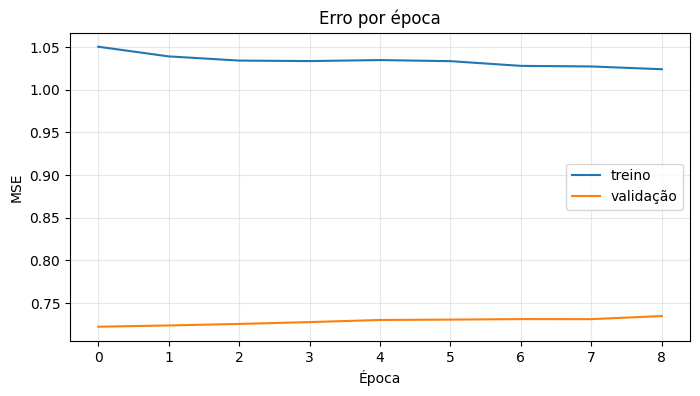

In [14]:
historico = extras["historico"]
plt.figure(figsize=(8, 4))
plt.plot(historico.history["loss"], label="treino")
plt.plot(historico.history["val_loss"], label="validação")
plt.title("Erro por época")
plt.xlabel("Época")
plt.ylabel("MSE")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

val < treino porque a validação é um período mais calmo (treino tem 2008, Brumadinho, Covid)

In [15]:
metricas_lstm = resultado_final["lstm"]
metricas_baseline = resultado_final["baseline"]
acerto_direcao = resultado_final["acerto_direcao_pct"]

print(f"Teste: {resultado_final['inicio_teste']} a {resultado_final['fim_teste']}")
display(pd.DataFrame({"LSTM": metricas_lstm, "Baseline": metricas_baseline}))
print(f"Acerto de direção: {acerto_direcao:.1f}%")

Teste: 2023-02-10 a 2026-10-28


,LSTM,Baseline
MAE,0.7020,0.6959
RMSE,0.9728,0.9657
MAPE_%,1.1944,1.1858


Acerto de direção: 52.3%


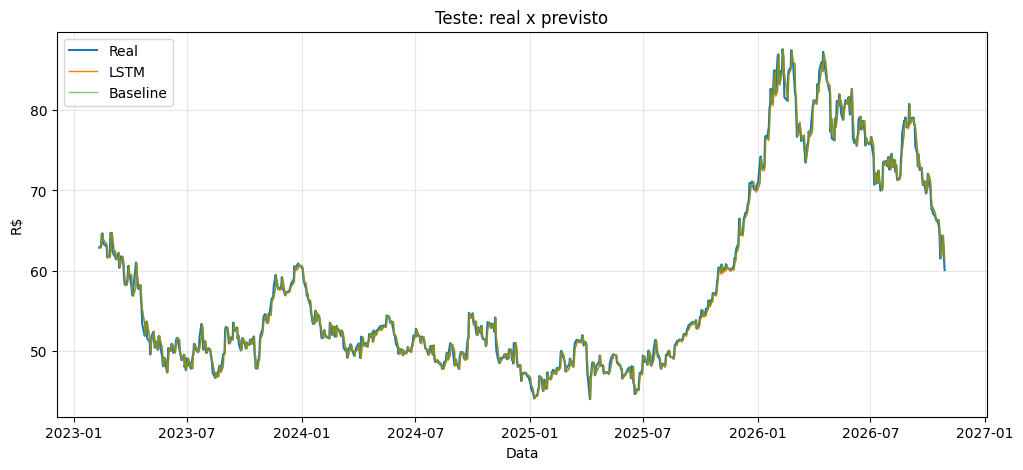

In [16]:
plt.figure(figsize=(12, 5))
plt.plot(extras["datas"], extras["real"], label="Real", linewidth=1.5)
plt.plot(extras["datas"], extras["previsto_lstm"], label="LSTM", linewidth=1)
plt.plot(extras["datas"], extras["preco_hoje"], label="Baseline", linewidth=1, alpha=0.6)
plt.title("Teste: real x previsto")
plt.xlabel("Data")
plt.ylabel("R$")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

o modelo tá "chutando a média"? (v2: desvio previsto 0,145% x real 1,6%)

In [17]:
retorno_previsto = extras["retorno_previsto"]
print("Variação prevista (%): min", round(retorno_previsto.min() * 100, 3),
      "| max", round(retorno_previsto.max() * 100, 3),
      "| desvio", round(retorno_previsto.std() * 100, 3))
print("Variação real no teste, desvio (%):", round(np.std(extras["real"] / extras["preco_hoje"] - 1) * 100, 3))

Variação prevista (%): min -0.363 | max 0.26 | desvio 0.117
Variação real no teste, desvio (%): 1.592


## Drift

guardo média/desvio de cada feature no treino. na API: (média últimos 60 dias - média treino) / desvio treino.
passou de 1 desvio → alerta (sinal p/ retreinar).

In [18]:
LIMITE_DRIFT = 1.0

periodo_treino = dados.iloc[:corte]
referencia_drift = {
    f: {"media": float(periodo_treino[f].mean()), "desvio": float(periodo_treino[f].std())}
    for f in FEATURES_FINAIS
}


def verificar_drift(features_recentes, referencia, limite=LIMITE_DRIFT):
    resultado = {}
    for f, ref in referencia.items():
        distancia = (features_recentes[f].mean() - ref["media"]) / ref["desvio"]
        resultado[f] = {"distancia": round(float(distancia), 3), "alerta": bool(abs(distancia) > limite)}
    return resultado


ultimos_60 = tabela[FEATURES_FINAIS].tail(JANELA)
pd.DataFrame(verificar_drift(ultimos_60, referencia_drift)).T

,distancia,alerta
retorno,-0.148,False
amplitude,-0.333,False
volume_rel,0.226,False
volatilidade_20,-0.797,False
dist_media_20,-0.378,False


## Salvar

vale_lstm.keras + scalers.joblib (X e y) + model_info.json → pasta model/ da API

In [19]:
modelo.save("vale_lstm.keras")
joblib.dump({"X": extras["scaler_X"], "y": extras["scaler_y"]}, "scalers.joblib")

info = {
    "ticker": TICKER,
    "janela_dias": JANELA,
    "features": FEATURES_FINAIS,
    "opcao_escolhida": ESCOLHA,
    "mercado": {nome: t for nome, t in MERCADO.items() if f"retorno_{nome}" in FEATURES_FINAIS},
    "alvo": "variacao_do_dia_seguinte",
    "dias_brutos_necessarios": JANELA + 21,  # janela + médias de 20 dias + 1ª variação
    "dados_inicio": str(df.index.min().date()),
    "dados_fim": str(df.index.max().date()),
    "treinado_em": datetime.now().isoformat(timespec="seconds"),
    "metricas_teste": {
        "periodo": f"{resultado_final['inicio_teste']} a {resultado_final['fim_teste']}",
        "lstm": metricas_lstm,
        "baseline": metricas_baseline,
        "acerto_direcao_pct": acerto_direcao,
    },
    "walk_forward": {
        "so_variacao_v2": resumir(wf_v2),
        "cinco_features_v3": resumir(wf_v3),
        "tecnicas_mais_mercado_v4": resumir(wf_v4),
    },
    "drift": {"limite_desvios": LIMITE_DRIFT, "referencia_treino": referencia_drift},
    "historico_versoes": {
        "v1_prever_preco": {"MAE": 1.2932, "RMSE": 1.7585, "MAPE_%": 2.0457},
        "v2_prever_variacao": {"MAE": 0.7233, "RMSE": 1.0321, "MAPE_%": 1.1724},
        "v3_walk_forward_desde_2015": {"so_variacao": 0.7731, "cinco_features": 0.7840, "baseline": 0.7684},
    },
}
with open("model_info.json", "w", encoding="utf-8") as f:
    json.dump(info, f, ensure_ascii=False, indent=2)

print(json.dumps(info, ensure_ascii=False, indent=2))

{
  "ticker": "VALE3.SA",
  "janela_dias": 60,
  "features": [
    "retorno",
    "amplitude",
    "volume_rel",
    "volatilidade_20",
    "dist_media_20"
  ],
  "opcao_escolhida": "5 features (v3)",
  "mercado": {},
  "alvo": "variacao_do_dia_seguinte",
  "dias_brutos_necessarios": 81,
  "dados_inicio": "2008-01-02",
  "dados_fim": "2026-10-29",
  "treinado_em": "2026-10-29T21:28:55",
  "metricas_teste": {
    "periodo": "2023-02-10 a 2026-10-28",
    "lstm": {
      "MAE": 0.702,
      "RMSE": 0.9728,
      "MAPE_%": 1.1944
    },
    "baseline": {
      "MAE": 0.6959,
      "RMSE": 0.9657,
      "MAPE_%": 1.1858
    },
    "acerto_direcao_pct": 52.34
  },
  "walk_forward": {
    "so_variacao_v2": {
      "MAE médio LSTM": 0.7709,
      "MAE médio baseline": 0.7698,
      "RMSE médio LSTM": 1.0304,
      "RMSE médio baseline": 1.0279,
      "acerto de direção médio %": 48.51,
      "períodos vencidos (de 5)": 2
    },
    "cinco_features_v3": {
      "MAE médio LSTM": 0.7678,
      

## Teste (simulando a API)

carrega só os arquivos salvos. preço previsto em cima do CloseBruto (preço real).

In [20]:
modelo_carregado = tf.keras.models.load_model("vale_lstm.keras")
scalers_carregados = joblib.load("scalers.joblib")
with open("model_info.json", encoding="utf-8") as f:
    info_carregada = json.load(f)

features_modelo = info_carregada["features"]
janela = info_carregada["janela_dias"]

df_recente = df.tail(120)
mercado_recente = mercado.loc[df_recente.index, list(info_carregada["mercado"])] if info_carregada["mercado"] else None
feats_recentes = preparar_features(df_recente, mercado_recente)[features_modelo].dropna().tail(janela)
assert len(feats_recentes) == janela, "dados insuficientes"

entrada = scalers_carregados["X"].transform(feats_recentes.values).reshape(1, janela, len(features_modelo))
variacao_prevista = scalers_carregados["y"].inverse_transform(modelo_carregado.predict(entrada, verbose=0))[0, 0]
ultimo_fechamento = df_recente["CloseBruto"].iloc[-1]
preco_previsto = ultimo_fechamento * (1 + variacao_prevista)

print(f"Último fechamento ({df_recente.index[-1].date()}): R$ {ultimo_fechamento:.2f}")
print(f"Variação prevista: {variacao_prevista * 100:+.2f}%")
print(f"Previsão próximo pregão: R$ {preco_previsto:.2f}")
print("Drift:", verificar_drift(feats_recentes, info_carregada["drift"]["referencia_treino"], info_carregada["drift"]["limite_desvios"]))

Último fechamento (2026-10-29): R$ 60.05
Variação prevista: +0.06%
Previsão próximo pregão: R$ 60.09
Drift: {'retorno': {'distancia': -0.148, 'alerta': False}, 'amplitude': {'distancia': -0.333, 'alerta': False}, 'volume_rel': {'distancia': 0.226, 'alerta': False}, 'volatilidade_20': {'distancia': -0.797, 'alerta': False}, 'dist_media_20': {'distancia': -0.378, 'alerta': False}}


versões p/ o requirements.txt

In [21]:
print("tensorflow =", tf.__version__)
print("numpy =", np.__version__)
print("pandas =", pd.__version__)
print("scikit-learn =", sklearn.__version__)
print("joblib =", joblib.__version__)
print("requests =", requests.__version__)

tensorflow = 2.20.0
numpy = 2.1.3
pandas = 2.3.3
scikit-learn = 1.6.1
joblib = 1.6.0
requests = 2.34.2
